# 01 — Exploratory data analysis: FER-2013 and RAF-DB

Class balance, sample images, image statistics, data-quality issues (blank images, duplicates, train/test leakage) and, when RAF-DB is available, its demographic make-up.

Figures are saved to `results/eda/` for the report.

In [1]:
import sys, hashlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent)) if Path.cwd().name == "notebooks" else None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

from src.common import ROOT
from src.datasets import CLASSES, fer2013_frames, rafdb_frame

FIG = ROOT / "results" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. FER-2013 class distribution

In [2]:
train, val, test = fer2013_frames(ROOT / "data/fer2013")
fer = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
fer["emotion"] = fer["label"].map(dict(enumerate(CLASSES)))

counts = fer.pivot_table(index="emotion", columns="split", values="path", aggfunc="count").reindex(CLASSES)[["train", "val", "test"]]
counts["train %"] = (100 * counts["train"] / counts["train"].sum()).round(1)
print(f"total images: {len(fer)}  |  imbalance ratio (max/min train): {counts['train'].max() / counts['train'].min():.1f}x")
counts

total images: 35887  |  imbalance ratio (max/min train): 16.6x


split,train,val,test,train %
emotion,,,,
angry,3596,399,958,13.9
disgust,392,44,111,1.5
fear,3687,410,1024,14.3
happy,6493,722,1774,25.1
sad,4347,483,1247,16.8
surprise,2854,317,831,11.0
neutral,4469,496,1233,17.3


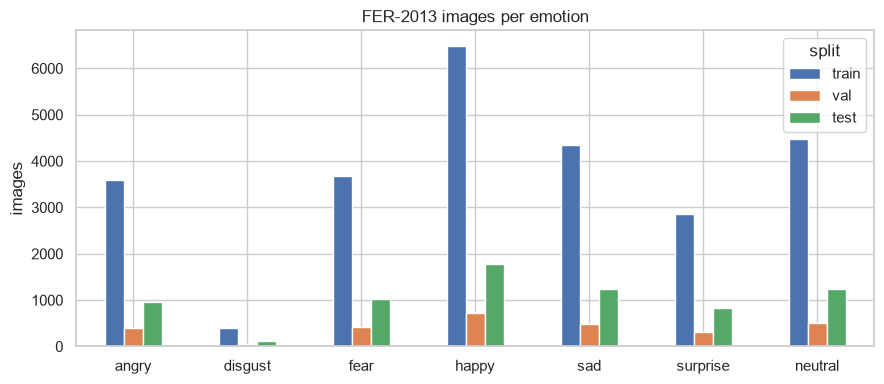

In [3]:
ax = counts[["train", "val", "test"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_title("FER-2013 images per emotion"); ax.set_ylabel("images"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "fer_class_distribution.png", dpi=150); plt.show()

## 2. Sample images per class

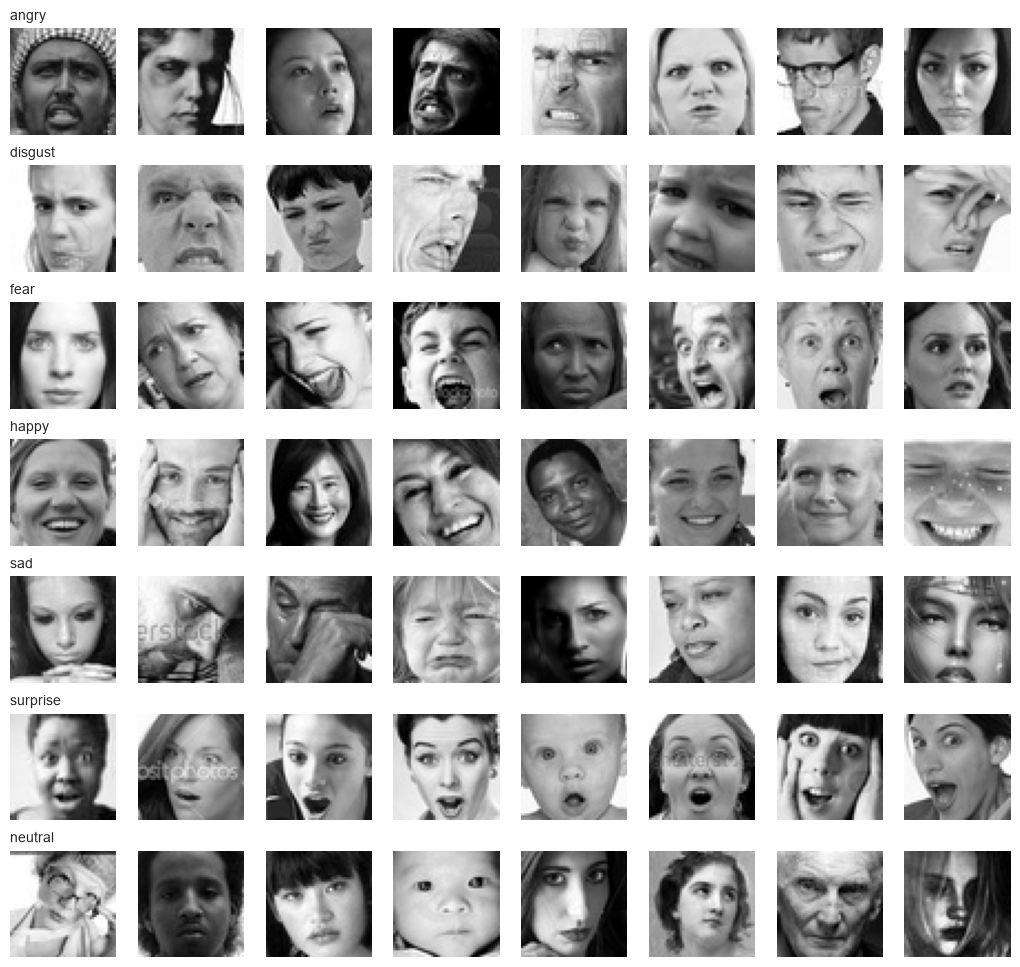

In [4]:
rng = np.random.default_rng(0)
k = 8
fig, axes = plt.subplots(len(CLASSES), k, figsize=(k * 1.3, len(CLASSES) * 1.4))
for r, cls in enumerate(CLASSES):
    paths = train.loc[train["label"] == r, "path"].sample(k, random_state=0)
    for c, p in enumerate(paths):
        axes[r, c].imshow(Image.open(p), cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "fer_samples.png", dpi=150); plt.show()

## 3. Image statistics

Load every image once (48x48 grayscale) to compute per-image stats and hashes.

In [5]:
def load(p):
    return np.asarray(Image.open(p).convert("L"), dtype=np.uint8)

arrs = [load(p) for p in tqdm(fer["path"], desc="loading")]
fer["mean"] = [a.mean() for a in arrs]
fer["std"] = [a.std() for a in arrs]
fer["md5"] = [hashlib.md5(a.tobytes()).hexdigest() for a in arrs]
print("all 48x48:", all(a.shape == (48, 48) for a in arrs))
fer.groupby("emotion")[["mean", "std"]].mean().reindex(CLASSES).round(1)

loading:   0%|          | 0/35887 [00:00<?, ?it/s]

all 48x48: True


,mean,std
emotion,,
angry,126.5,54.6
disgust,135.1,51.8
fear,135.4,54.9
happy,129.1,53.1
sad,121.0,53.6
surprise,146.3,55.2
neutral,123.9,54.3


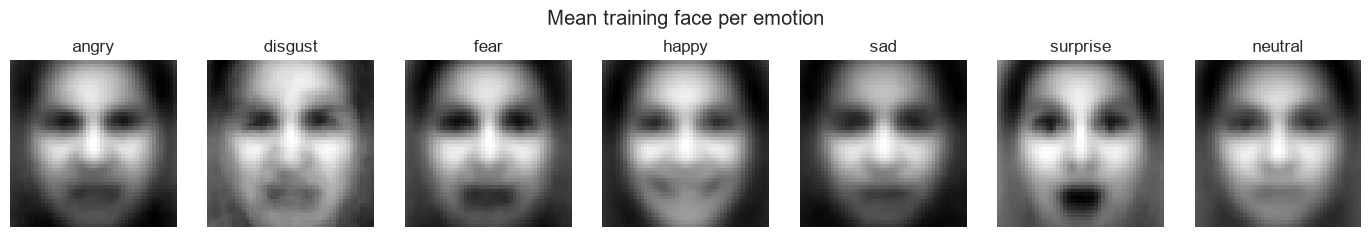

In [6]:
# mean face per emotion
fig, axes = plt.subplots(1, len(CLASSES), figsize=(14, 2.4))
for ax, (i, cls) in zip(axes, enumerate(CLASSES)):
    idx = np.where((fer["label"] == i) & (fer["split"] == "train"))[0]
    ax.imshow(np.mean([arrs[j] for j in idx], axis=0), cmap="gray"); ax.set_title(cls); ax.axis("off")
plt.suptitle("Mean training face per emotion"); plt.tight_layout()
plt.savefig(FIG / "fer_mean_faces.png", dpi=150); plt.show()

## 4. Data-quality checks

FER-2013 was scraped from Google image search, so it contains blank / non-face images, exact duplicates and duplicates shared between train and test (leakage).

near-blank images (pixel std < 5): 14
emotion  angry  happy  neutral  sad  surprise
split                                        
test         1      1        0    0         0
train        7      1        2    1         1


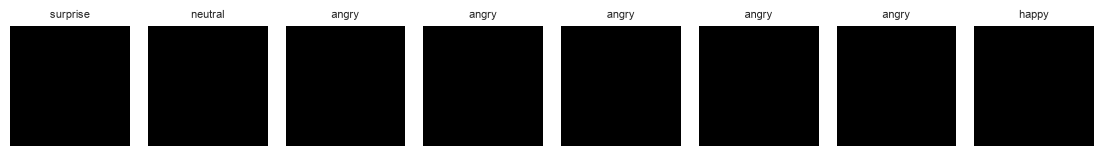

In [7]:
blank = fer[fer["std"] < 5]
print(f"near-blank images (pixel std < 5): {len(blank)}")
print(blank.groupby(["split", "emotion"]).size().unstack(fill_value=0))

if len(blank):
    show = blank.head(8)
    fig, axes = plt.subplots(1, len(show), figsize=(len(show) * 1.4, 1.8), squeeze=False)
    for ax, (_, r) in zip(axes[0], show.iterrows()):
        ax.imshow(Image.open(r["path"]), cmap="gray", vmin=0, vmax=255); ax.set_title(r["emotion"], fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG / "fer_blank_examples.png", dpi=150); plt.show()

In [8]:
dup = fer[fer.duplicated("md5", keep=False)]
groups = dup.groupby("md5")
conflicting = groups.filter(lambda g: g["label"].nunique() > 1)
leak = groups.filter(lambda g: g["split"].nunique() > 1 and "test" in set(g["split"]))
print(f"images that have an exact duplicate: {len(dup)} ({dup['md5'].nunique()} unique)")
print(f"duplicate groups with conflicting labels: {conflicting['md5'].nunique()}  -> label-noise evidence")
print(f"test images that also appear in train/val: {leak.loc[leak['split'] == 'test', 'md5'].nunique()}  -> leakage")

images that have an exact duplicate: 3369 (1516 unique)
duplicate groups with conflicting labels: 57  -> label-noise evidence
test images that also appear in train/val: 531  -> leakage


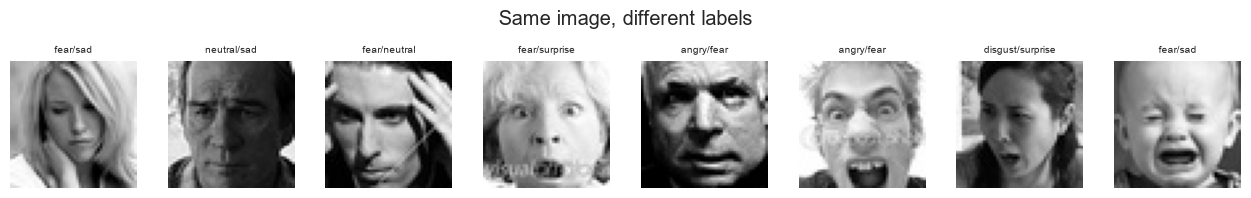

In [9]:
# a few duplicates with conflicting labels
show = conflicting.groupby("md5").head(1).head(8)
if len(show):
    fig, axes = plt.subplots(1, len(show), figsize=(len(show) * 1.6, 2), squeeze=False)
    for ax, (h, _) in zip(axes[0], show.iterrows()):
        g = conflicting[conflicting["md5"] == show.loc[h, "md5"]]
        ax.imshow(Image.open(g.iloc[0]["path"]), cmap="gray"); ax.axis("off")
        ax.set_title("/".join(sorted(set(g["emotion"]))), fontsize=7)
    plt.suptitle("Same image, different labels"); plt.tight_layout()
    plt.savefig(FIG / "fer_conflicting_labels.png", dpi=150); plt.show()

## 5. RAF-DB (cross-dataset test set and demographics)

Runs only once RAF-DB is in `data/rafdb`.

In [10]:
raf_root = ROOT / "data/rafdb"
if not (raf_root / "EmoLabel").exists():
    print("RAF-DB not available yet - skipping")
    raf = None
else:
    raf = pd.concat([rafdb_frame(raf_root, "train").assign(split="train"),
                     rafdb_frame(raf_root, "test").assign(split="test")])
    raf["emotion"] = raf["label"].map(dict(enumerate(CLASSES)))
    dist = pd.DataFrame({
        "FER-2013 train %": fer[fer.split == "train"]["emotion"].value_counts(normalize=True) * 100,
        "RAF-DB test %": raf[raf.split == "test"]["emotion"].value_counts(normalize=True) * 100,
    }).reindex(CLASSES).round(1)
    display(dist)

RAF-DB not available yet - skipping


In [11]:
if raf is not None and "gender" in raf:
    test = raf[raf.split == "test"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    for ax, col in zip(axes, ["gender", "race", "age"]):
        test[col].value_counts().sort_index().plot.bar(ax=ax, rot=0); ax.set_title(f"RAF-DB test: {col}")
    plt.tight_layout(); plt.savefig(FIG / "rafdb_demographics.png", dpi=150); plt.show()

    for col in ["gender", "race", "age"]:
        ct = pd.crosstab(test[col], test["emotion"], normalize="index").reindex(columns=CLASSES) * 100
        plt.figure(figsize=(8, 0.6 * len(ct) + 1.2))
        sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar=False)
        plt.title(f"Emotion distribution (%) within each {col} group"); plt.tight_layout()
        plt.savefig(FIG / f"rafdb_emotion_by_{col}.png", dpi=150); plt.show()

## 6. Findings (for the report's Data section)

Fill in from the outputs above:

- **Imbalance:** ...
- **Data quality:** ...
- **Leakage / label noise:** ...
- **RAF-DB vs FER-2013:** ...
- **Demographic balance in RAF-DB:** ...
- **Implications:** class-weighted loss, macro-F1 as the main metric, report per-subgroup CIs because some groups are small.